# 双面 X-ray 2D kinoform 透镜与侧向支撑

依次运行全部单元。尺寸输入为 µm，能量为 keV，导出 STL 坐标为 **mm**。光轴为 z 轴，图示的圆形透镜位于 xy 平面；支撑从透镜下方的圆周向 −y 延伸，呈立柱状，与透镜连成单一实体。底座表面位于立柱底部，未包含额外基板。N 仅用于计算，不生成 N 片阵列。

每面抛物面轮廓为 $r^2/(2R)$，折叠周期 $H=\lambda/\delta$，总厚度为 $t+2[(r^2/2R)\bmod H]$。两面各有完整的 2π 厚度跳变；近轴薄透镜焦距为 $f_1=R/(2\delta)$，N 片紧密排列时 $f_N=R/(2N\delta)$。材料密度及组成仅为示例，请按实际材料输入或覆盖 δ。支撑在光学口径外，不遮挡入射孔径。

加工误差模型：横向以方形像素中心采样，z 方向以层厚量化每个曲面；两面误差完全相关，N 片完全相同并对齐。分析固定设计焦平面轴上相干峰值，不考虑重新对焦、实际表面粗糙度、制造偏差或完整焦斑。横向网格对齐方式固定为中心对齐，真实工艺应做偏移及误差统计。STL 仍输出理想几何。

参考：[2π 步高](https://pmc.ncbi.nlm.nih.gov/articles/PMC9641566/)、[双面透镜焦距](https://onlinelibrary.wiley.com/doi/abs/10.1107/S1600577519017235)、[IP-S 组成](https://pmc.ncbi.nlm.nih.gov/articles/PMC6070906/)、[SU-8 组成](https://journals.iucr.org/s/issues/2004/03/00/fd5003/index.html)。

In [60]:
# 缺少依赖时运行：pip install numpy matplotlib trimesh xraydb
import numpy as np
import matplotlib.pyplot as plt
import trimesh, xraydb
from pathlib import Path

In [76]:
# 长度：µm；能量：keV
D, R, t = 300.0, 20.0, 50.0  # 透镜直径、单面曲率半径、中心厚度
c, h = 100.0, 100.0             # 侧向立柱宽度、最低点到柱底的距离
E, N = 20.0, 10                # 能量、累积透镜数
material = "IP-S"               # IP-S 或 SU-8
density_g_cm3 = 1.2            # 示例值，按固化材料修改
delta_override = None          # 正数可直接指定 δ
lateral_resolution_nm = 200.0  # 横向像素尺寸，nm
layer_height_nm = 500.0         # z 方向层厚，nm
peak_target = 0.80              # 允许的相对设计焦点峰值下限
error_samples = 1001           # 误差图和聚焦估算的二维采样点数
stl_precision_um = 0.1        # STL 单面曲面高度误差目标，µm（10 nm）
stl_chord_tolerance_um = 0.1 # STL 圆周弦高误差上限，µm（10 nm）
stl_max_faces = 5000000        # 防止网格过大；需要时可增大
output_stl = Path("kinoform_3D.stl")

if not all(np.isfinite(v) and v > 0 for v in (D,R,t,c,h,E,density_g_cm3,stl_precision_um,stl_chord_tolerance_um,lateral_resolution_nm,layer_height_nm)):
    raise ValueError("长度、能量、密度和精度必须为有限正数")
if c >= D or not isinstance(N,int) or N < 1 or not isinstance(error_samples,int) or error_samples < 101:
    raise ValueError("要求 c < D，N 为正整数，error_samples >= 101")
formulas = {"IP-S":"C100H172N9O37", "SU-8":"C22H24O4"}
if material not in formulas: raise ValueError("material 必须是 IP-S 或 SU-8")
delta = float(xraydb.xray_delta_beta(formulas[material], density_g_cm3, E*1000)[0]) if delta_override is None else float(delta_override)
if not np.isfinite(delta) or delta <= 0: raise ValueError("delta 必须为正数")
wavelength_um=1.239841984e-3/E
H=wavelength_um/delta
rmax=D/2
print(f"{material}: δ={delta:.6g}, λ={wavelength_um:.8g} µm, 2π 高度={H:.4f} µm")

IP-S: δ=6.73325e-07, λ=6.1992099e-05 µm, 2π 高度=92.0687 µm


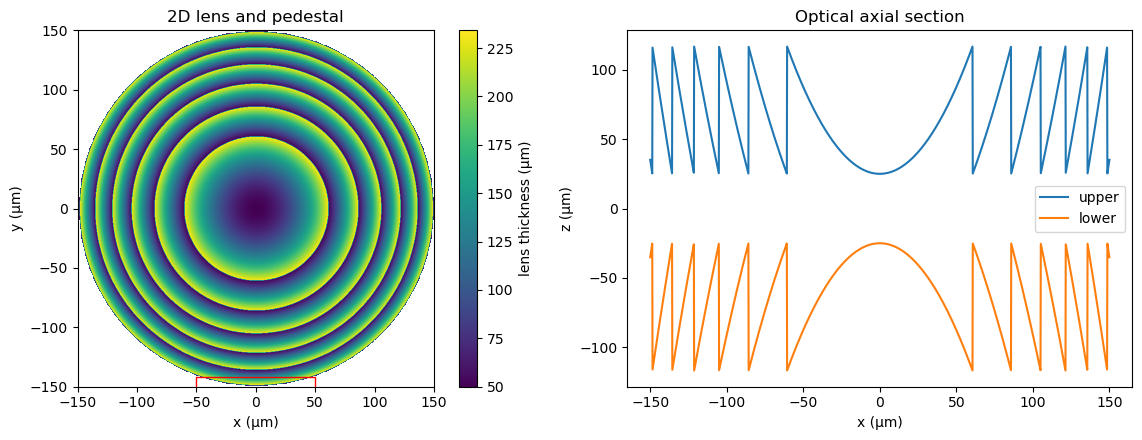

In [77]:
# 2D 理想厚度分布与截面
x=np.linspace(-rmax,rmax,1601)
xx,yy=np.meshgrid(x[::2],x[::2]); rr=np.hypot(xx,yy)
thickness=t+2*np.remainder(rr**2/(2*R),H); thickness[rr>rmax]=np.nan
profile=np.remainder(x*x/(2*R),H)
fig,(a,b)=plt.subplots(1,2,figsize=(12,4.5))
im=a.imshow(thickness,extent=[-rmax,rmax,-rmax,rmax],origin="lower",cmap="viridis")
fig.colorbar(im,ax=a,label="lens thickness (µm)")
a.add_patch(plt.Rectangle((-c/2,-rmax-h),c,h+rmax-np.sqrt(rmax*rmax-(c/2)**2),fill=False,color="red"))
a.set(xlabel="x (µm)",ylabel="y (µm)",title="2D lens and pedestal")
b.plot(x,t/2+profile,label="upper"); b.plot(x,-t/2-profile,label="lower")
b.set(xlabel="x (µm)",ylabel="z (µm)",title="Optical axial section"); b.legend()
fig.tight_layout(); plt.show()

In [78]:
# 焦距：N 片紧密排列的薄透镜近似
f_single_um = R/(2*delta)
print(f"单片理论焦距: {f_single_um/1e6:.6g} m")
print(f"{N} 片理论焦距: {f_single_um/N/1e6:.6g} m")
print(f"{2*N} 片理论焦距: {f_single_um/2/N/1e6:.6g} m")
print(f"{3*N} 片理论焦距: {f_single_um/3/N/1e6:.6g} m")
print("片间距不可忽略时需使用传输矩阵。")

单片理论焦距: 14.8517 m
10 片理论焦距: 1.48517 m
20 片理论焦距: 0.742584 m
30 片理论焦距: 0.495056 m
片间距不可忽略时需使用传输矩阵。


## 吸收与透射：单片、N 片及中心厚度扫描

假设均匀平行入射、N 片完全同轴且光线沿光轴直线穿过相同位置，忽略片间衍射及散射光重新进入孔径。沿材料路径使用 Beer–Lambert 定律：$T=\exp(-\mu_{\rm total}NL)$。这里总衰减包含光电吸收和散射；光电吸收比例按竞争过程计算为 $A_{\rm photo}=\frac{\mu_{\rm photo}}{\mu_{\rm total}}(1-T)$，它与总损失 $1-T$ 不同。系数由 `xraydb.material_mu` 按当前材料、密度和能量计算；`delta_override` 只影响相位与轮廓，不改变吸收系数。

下面扫描 t 时保持 R、D、能量、材料及 kinoform 面形不变；平均值按圆形孔径面积加权，并对每个 kinoform 环解析积分。二维图受显示采样精度限制。

光电吸收系数: 0.385375 cm⁻¹；总衰减系数: 0.679594 cm⁻¹
总衰减长度: 1.471e+04 µm
单片平均透射率: 0.990497；平均光电吸收比例: 0.005389
10 片平均透射率: 0.909480；平均光电吸收比例: 0.051331


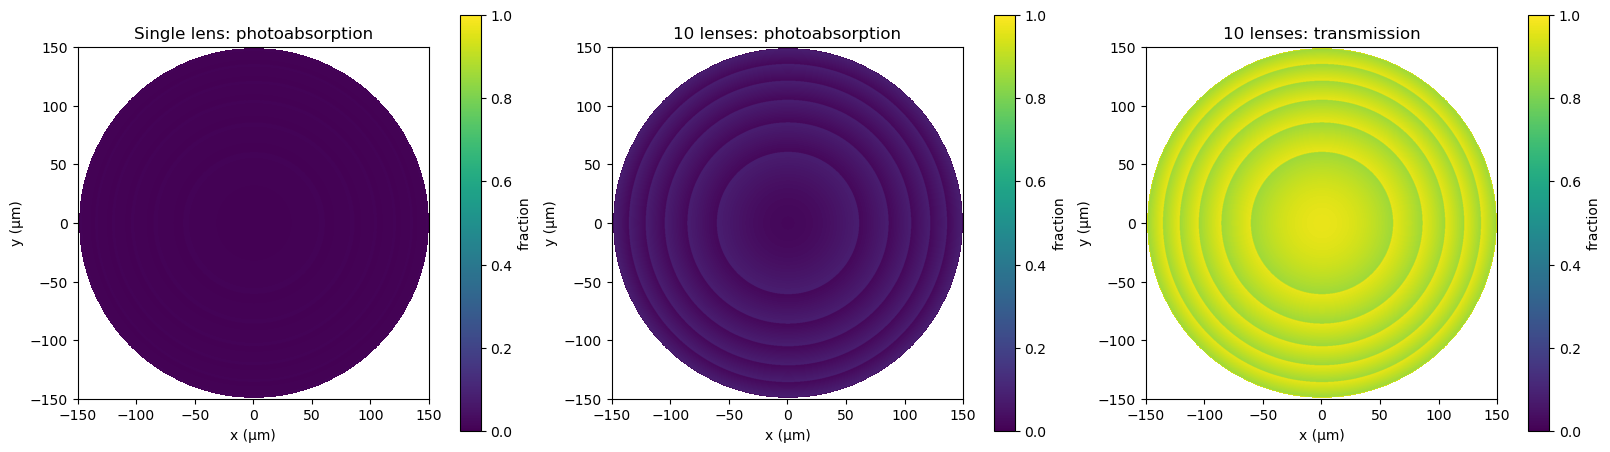

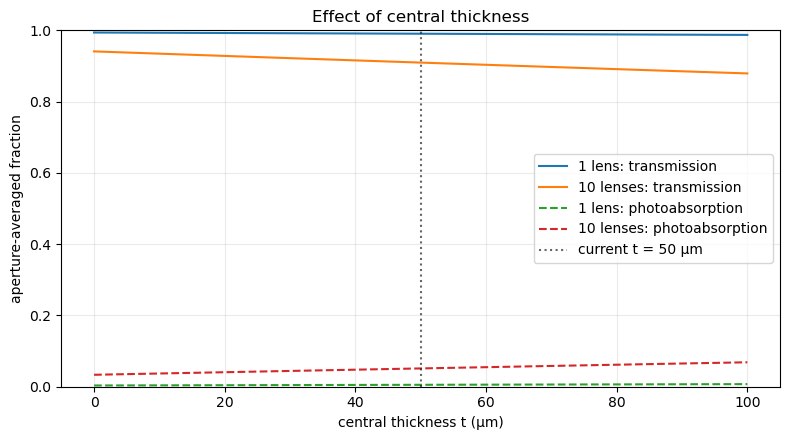

In [79]:
# 厚度扫描参数（µm）；当前 t 另以标记显示
t_scan_min_um = 0.0
t_scan_max_um = max(50.0, 2*t)
t_scan_points = 101
absorption_plot_samples = 1001
if not (0 <= t_scan_min_um < t_scan_max_um and t_scan_points >= 2 and absorption_plot_samples >= 101):
    raise ValueError("请检查 t 扫描范围和采样点数")

# material_mu 返回 cm^-1；与 µm 厚度相乘时转换为 10^-4 cm。
mu_photo_cm = float(xraydb.material_mu(formulas[material], E*1000, density=density_g_cm3, kind="photo"))
mu_total_cm = float(xraydb.material_mu(formulas[material], E*1000, density=density_g_cm3, kind="total"))
if not (np.isfinite(mu_total_cm) and np.isfinite(mu_photo_cm) and 0 <= mu_photo_cm <= mu_total_cm and mu_total_cm > 0):
    raise ValueError("材料衰减系数无效，请检查材料与能量")
photo_fraction = mu_photo_cm/mu_total_cm

# 在每个相位周期内对径向积分作解析处理，避免窄环欠采样。
edge_u = rmax*rmax/(2*R)  # u = r²/(2R), 孔径面积权重在 u 上均匀
full_zones = int(np.floor(edge_u/H))
last_width = edge_u-full_zones*H
def area_mean_transmission(center_thickness_um, lens_count):
    a = mu_total_cm*1e-4*lens_count
    zone_integral = -np.expm1(-2*a*H)/(2*a)
    last_integral = -np.expm1(-2*a*last_width)/(2*a)
    return np.exp(-a*np.asarray(center_thickness_um))*(full_zones*zone_integral+last_integral)/edge_u

coordinate = np.linspace(-rmax,rmax,absorption_plot_samples)
ax_x,ax_y = np.meshgrid(coordinate,coordinate)
radius = np.hypot(ax_x,ax_y)
inside = radius <= rmax
path_um = t+2*np.remainder(radius**2/(2*R),H)
trans_one = np.exp(-mu_total_cm*1e-4*path_um)
trans_stack = np.exp(-mu_total_cm*1e-4*N*path_um)
abs_one = photo_fraction*(1-trans_one)
abs_stack = photo_fraction*(1-trans_stack)
mean_one = float(area_mean_transmission(t,1))
mean_stack = float(area_mean_transmission(t,N))
print(f"光电吸收系数: {mu_photo_cm:.6g} cm⁻¹；总衰减系数: {mu_total_cm:.6g} cm⁻¹")
print(f"总衰减长度: {1/mu_total_cm*1e4:.4g} µm")
print(f"单片平均透射率: {mean_one:.6f}；平均光电吸收比例: {photo_fraction*(1-mean_one):.6f}")
print(f"{N} 片平均透射率: {mean_stack:.6f}；平均光电吸收比例: {photo_fraction*(1-mean_stack):.6f}")

extent=[-rmax,rmax,-rmax,rmax]
fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for ax,data,title in ((axes[0],abs_one,"Single lens: photoabsorption"),
                      (axes[1],abs_stack,f"{N} lenses: photoabsorption"),
                      (axes[2],trans_stack,f"{N} lenses: transmission")):
    im=ax.imshow(np.where(inside,data,np.nan),origin="lower",extent=extent,cmap="viridis",vmin=0,vmax=1)
    ax.set(xlabel="x (µm)",ylabel="y (µm)",title=title)
    fig.colorbar(im,ax=ax,label="fraction")
plt.show()

t_values=np.linspace(t_scan_min_um,t_scan_max_um,t_scan_points)
T1=area_mean_transmission(t_values,1); TN=area_mean_transmission(t_values,N)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(t_values,T1,label="1 lens: transmission")
ax.plot(t_values,TN,label=f"{N} lenses: transmission")
ax.plot(t_values,photo_fraction*(1-T1),"--",label="1 lens: photoabsorption")
ax.plot(t_values,photo_fraction*(1-TN),"--",label=f"{N} lenses: photoabsorption")
ax.axvline(t,color="black",alpha=.6,linestyle=":",label=f"current t = {t:g} µm")
ax.set(xlabel="central thickness t (µm)",ylabel="aperture-averaged fraction",ylim=(0,1),title="Effect of central thickness")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
if not t_scan_min_um <= t <= t_scan_max_um:
    print("当前 t 不在扫描范围内；请调整扫描范围以在图中显示。")

当前 R=20 µm, D=300 µm；最外完整环宽约 12.95 µm；横向像素 0.2 µm，层高 0.5 µm
单独横向像素化相对峰值: 0.8389
单独 z 层纹相对峰值: 0.9618
两者叠加相对峰值: 0.8071；峰值损失 19.29%
采样数减半时叠加结果: 0.8072；差值 9.207e-05


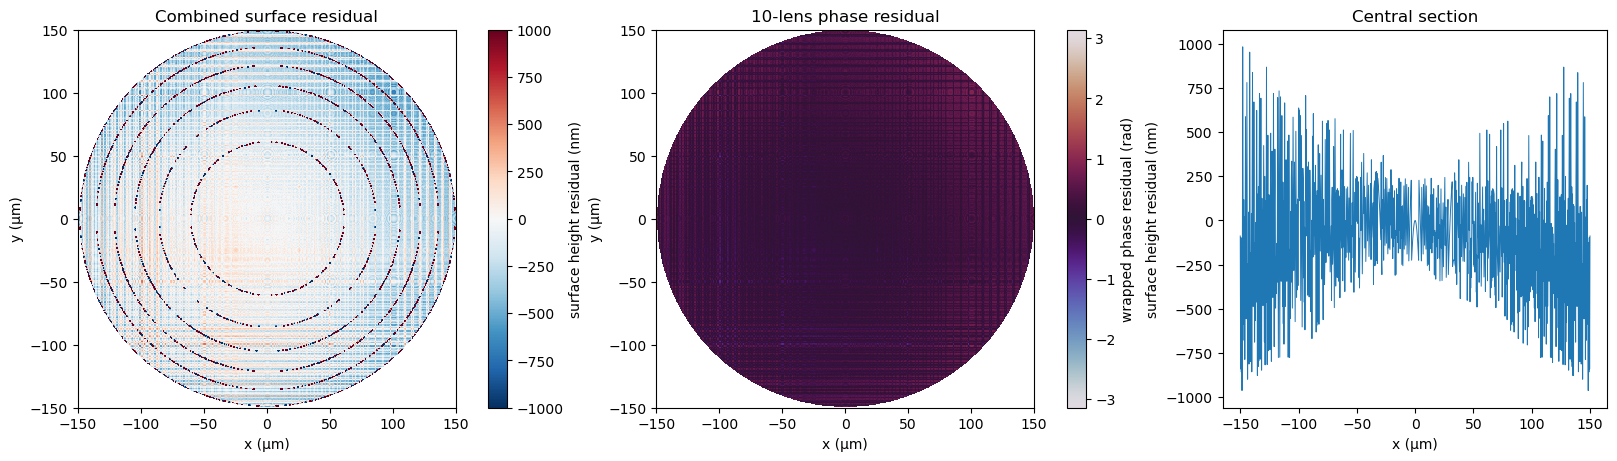

注意：误差图采样不足以解析每个横向像素；可增加 error_samples，峰值积分另用等面积采样。


In [80]:
# 加工误差：横向像素化 + z 层纹；每面独立叠加两类误差。
pitch=lateral_resolution_nm/1000.0
layer=layer_height_nm/1000.0
if not 0 < peak_target <= 1: raise ValueError("peak_target 必须在 (0, 1] 内")
if layer >= H: print("警告：层高不小于 2π 高度，层纹模型不再适合精细 kinoform。")

def surfaces(x,y, radius, aperture_D):
    """理想、横向像素化、层高量化、两者叠加的单面 sag。"""
    rr2=x*x+y*y
    ideal=np.remainder(rr2/(2*radius),H)
    px=np.round(x/pitch)*pitch; py=np.round(y/pitch)*pitch
    # 口径内光线的横向网格中心可能在圆外，外推同一抛物轮廓。
    lateral=np.remainder((px*px+py*py)/(2*radius),H)
    layered=np.round(ideal/layer)*layer
    combined=np.round(lateral/layer)*layer
    return ideal,lateral,layered,combined

def pupil_points(count, diameter):
    # 等面积确定性采样；无需保存大型规则网格。
    i=np.arange(count,dtype=float)
    rr=(diameter/2)*np.sqrt((i+.5)/count)
    theta=2*np.pi*np.remainder(i*0.6180339887498949,1.0)
    return rr*np.cos(theta),rr*np.sin(theta)

def assess(radius, diameter, count):
    x,y=pupil_points(count,diameter)
    ideal,lat,z,combined=surfaces(x,y,radius,diameter)
    # 吸收对应理想厚度，聚焦质量归一化至相同吸收的理想透镜。
    weights=np.exp(-mu_total_cm*1e-4*N*(t+2*ideal)/2)
    factor=-2*np.pi*delta*N/wavelength_um
    def peak(s):
        phase=factor*2*(s-ideal)
        return float(abs(np.sum(weights*np.exp(1j*phase))/np.sum(weights))**2)
    return np.array([peak(lat),peak(z),peak(combined)])

analysis_samples=131072
values=assess(R,D,analysis_samples)
half_values=assess(R,D,analysis_samples//2)
outer_zone_width=np.sqrt(2*R*H*int((D/2)**2/(2*R*H)))-np.sqrt(2*R*H*max(0,int((D/2)**2/(2*R*H))-1)) if (D/2)**2/(2*R*H)>=1 else D/2
print(f"当前 R={R:g} µm, D={D:g} µm；最外完整环宽约 {outer_zone_width:.4g} µm；横向像素 {pitch:g} µm，层高 {layer:g} µm")
print(f"单独横向像素化相对峰值: {values[0]:.4f}")
print(f"单独 z 层纹相对峰值: {values[1]:.4f}")
print(f"两者叠加相对峰值: {values[2]:.4f}；峰值损失 {(1-values[2])*100:.2f}%")
print(f"采样数减半时叠加结果: {half_values[2]:.4f}；差值 {abs(values[2]-half_values[2]):.4g}")
if abs(values[2]-half_values[2]) > 0.01: print("警告：采样尚未收敛，请提高 analysis_samples。")

# 面形实际高度残差和相位残差；跨 2π 台阶的相位用复指数折回。
grid=np.linspace(-rmax,rmax,error_samples)
ex,ey=np.meshgrid(grid,grid); mask=ex*ex+ey*ey<=rmax*rmax
ideal,lat,z,combined=surfaces(ex,ey,R,D)
height_error=combined-ideal
phase=-2*np.pi*delta*N*2*height_error/wavelength_um
wrapped_phase=np.angle(np.exp(1j*phase))
fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
im=axes[0].imshow(np.where(mask,height_error*1000,np.nan),origin="lower",extent=[-rmax,rmax,-rmax,rmax],cmap="RdBu_r",vmin=-1000,vmax=1000)

fig.colorbar(im,ax=axes[0],label="surface height residual (nm)")
axes[0].set(title="Combined surface residual",xlabel="x (µm)",ylabel="y (µm)")
im=axes[1].imshow(np.where(mask,wrapped_phase,np.nan),origin="lower",extent=[-rmax,rmax,-rmax,rmax],cmap="twilight",vmin=-np.pi,vmax=np.pi)
fig.colorbar(im,ax=axes[1],label="wrapped phase residual (rad)")
axes[1].set(title=f"{N}-lens phase residual",xlabel="x (µm)",ylabel="y (µm)")
mid=error_samples//2
axes[2].plot(grid,np.where(mask,height_error*1000,np.nan)[mid],linewidth=.7)
axes[2].set(title="Central section",xlabel="x (µm)",ylabel="surface height residual (nm)")
plt.show()
if 2*rmax/(error_samples-1)>pitch/2: print("注意：误差图采样不足以解析每个横向像素；可增加 error_samples，峰值积分另用等面积采样。")

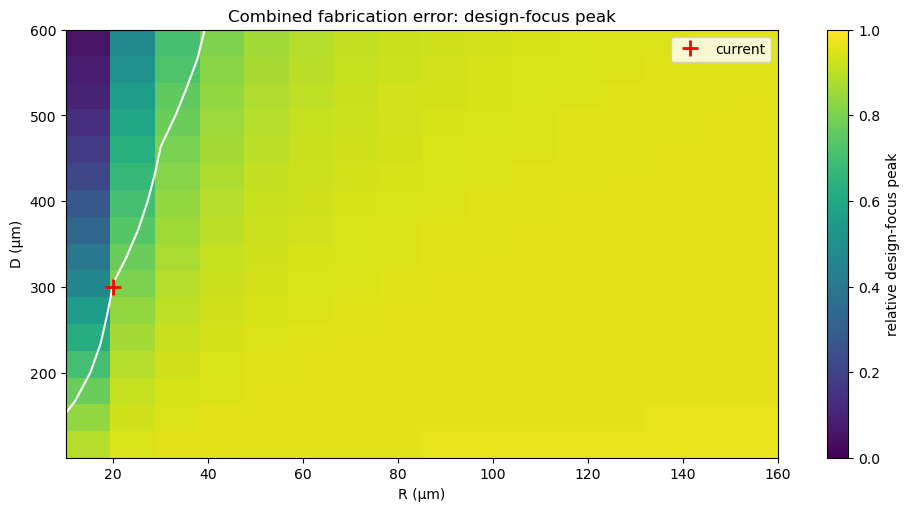

筛选目标：设计焦点相对峰值 ≥ 0.800，优先最大 D、再最小 R。
候选：R=40 µm，D=600 µm；粗扫描峰值=0.8081，复核=0.8072
候选理论焦距（10 片）: 2.97034 m
候选仅在给定扫描范围和误差模型中有效；请结合目标焦距、透射率及打印能力选择。
当前设计峰值 0.8071；扫描采样数 32768，建议提高采样数检查收敛。
保持 D=300 µm 时，扫描中最小候选 R=20 µm；复核峰值=0.8071，10 片焦距=1.48517 m。


In [81]:
# 扫描制造精度下的 R、D 设计空间；可按目标焦距和设备能力调整范围。
R_scan_um=np.linspace(10,160,16)
D_scan_um=np.linspace(max(c+1,100),600,16)
scan_samples=32768
if np.any(R_scan_um<=0) or np.any(D_scan_um<=c) or scan_samples<1024:
    raise ValueError("扫描范围必须为正，D 必须大于支撑宽度 c")
score=np.empty((len(D_scan_um),len(R_scan_um)))
for i,d_test in enumerate(D_scan_um):
    for j,r_test in enumerate(R_scan_um):
        score[i,j]=assess(r_test,d_test,scan_samples)[2]
fig,ax=plt.subplots(figsize=(9,5),constrained_layout=True)
im=ax.imshow(score,origin="lower",aspect="auto",extent=[R_scan_um[0],R_scan_um[-1],D_scan_um[0],D_scan_um[-1]],vmin=0,vmax=1,cmap="viridis")
fig.colorbar(im,ax=ax,label="relative design-focus peak")
if score.min()<=peak_target<=score.max():
    ax.contour(R_scan_um,D_scan_um,score,levels=[peak_target],colors="white")
ax.plot(R,D,"r+",markersize=12,markeredgewidth=2,label="current")
ax.set(xlabel="R (µm)",ylabel="D (µm)",title="Combined fabrication error: design-focus peak")
ax.legend(); plt.show()
# 排序规则：满足目标的候选中先最大 D，再在同一 D 选择最小 R。
candidates=np.argwhere(score>=peak_target)
if len(candidates)==0:
    print("扫描范围内没有满足目标的候选；请扩大 R、减小 D 或改善加工精度。")
else:
    best_i=max(candidates[:,0]); best_j=min(candidates[candidates[:,0]==best_i,1])
    recommend_D=float(D_scan_um[best_i]); recommend_R=float(R_scan_um[best_j])
    refined=assess(recommend_R,recommend_D,analysis_samples)[2]
    print(f"筛选目标：设计焦点相对峰值 ≥ {peak_target:.3f}，优先最大 D、再最小 R。")
    print(f"候选：R={recommend_R:g} µm，D={recommend_D:g} µm；粗扫描峰值={score[best_i,best_j]:.4f}，复核={refined:.4f}")
    print(f"候选理论焦距（{N} 片）: {recommend_R/(2*N*delta)/1e6:.6g} m")
    if refined < peak_target: print("复核未达目标；请提高 scan_samples 后重新扫描。")
    print("候选仅在给定扫描范围和误差模型中有效；请结合目标焦距、透射率及打印能力选择。")
print(f"当前设计峰值 {values[2]:.4f}；扫描采样数 {scan_samples}，建议提高采样数检查收敛。")
# 单独保持当前 D，扫描 R，便于比较现有口径的改进方案。
if D > c:
    same_D_scores=np.array([assess(r_test,D,scan_samples)[2] for r_test in R_scan_um])
    valid=np.flatnonzero(same_D_scores>=peak_target)
    if len(valid):
        candidate_R=float(R_scan_um[valid[0]])
        checked=assess(candidate_R,D,analysis_samples)[2]
        print(f"保持 D={D:g} µm 时，扫描中最小候选 R={candidate_R:g} µm；复核峰值={checked:.4f}，{N} 片焦距={candidate_R/(2*N*delta)/1e6:.6g} m。")
        if checked < peak_target: print("复核未达目标，请提高 scan_samples 后重新扫描。")
    else:
        print("保持当前 D 时，扫描范围内没有达到目标的 R。")


### STL 网格精度

`stl_precision_um` 是单面抛物面高度插值的目标预算（径向与周向各分配一半）；`stl_chord_tolerance_um` 单独约束圆周轮廓弦高。程序精确插入每个 2π 阶跃半径和支撑连接角度。打印出的误差是针对理想抛物面的几何估计，不包括 STL float32、打印机误差、切片或阶跃处加工误差；进一步减小精度参数可以检查网格收敛。STL 为理想几何，制造像素化和层纹不写入 STL。

In [82]:
# STL 精度同时约束径向、周向的抛物面高度插值和圆周轮廓弦高。
# 相位折叠半径与支撑边界精确插入，竖直阶跃不会被斜坡替代。
# 均分面形误差预算：径向抛物面插值和周向弦向插值各占一半。
# 周向采样还需控制曲面 z 的误差：单独控制圆轮廓弦高是不够的。
radial_step=np.sqrt(8*R*(stl_precision_um/2))
angle_surface=2*np.arcsin(min(1.0,np.sqrt(2*R*(stl_precision_um/2))/rmax))
angle_outline=2*np.arccos(np.clip(1-stl_chord_tolerance_um/rmax,-1,1))
angular_segments=max(12,int(np.ceil(2*np.pi/min(angle_surface,angle_outline))))
zone_count=int(np.floor(rmax*rmax/(2*R*H)))
zones=np.sqrt(2*R*H*np.arange(1,zone_count+1)); zones=zones[zones<rmax-1e-9]
breaks=np.unique(np.r_[0.,zones,rmax])
alpha=np.arcsin(c/(2*rmax))
theta=np.sort(np.unique(np.r_[np.arange(angular_segments)*2*np.pi/angular_segments, 3*np.pi/2-alpha,3*np.pi/2+alpha]))
nt=len(theta)
# 预估三角面，过大时提前退出，避免内存耗尽。
radial_subdivisions=sum(int(np.ceil((right-left)/radial_step)) for left,right in zip(breaks[:-1],breaks[1:]))
estimated_faces=4*nt*radial_subdivisions+4*nt*len(zones)+8*nt
if estimated_faces > stl_max_faces:
    raise ValueError(f"预计约 {estimated_faces:,} 个三角面，超过 stl_max_faces={stl_max_faces:,}；请提高限制或适当放宽精度")
max_radial_actual=max((right-left)/int(np.ceil((right-left)/radial_step)) for left,right in zip(breaks[:-1],breaks[1:]))
angle_max=np.max(np.diff(np.r_[theta,theta[0]+2*np.pi]))
radial_error=max_radial_actual**2/(8*R)
angular_error=rmax**2*np.sin(angle_max/2)**2/(2*R)
outline_error=rmax*(1-np.cos(angle_max/2))
print(f"预估三角面: {estimated_faces:,}；径向分段: {radial_subdivisions}；周向分段: {nt}")
print(f"径向/周向面形误差估计上限: {radial_error*1000:.3f} / {angular_error*1000:.3f} nm；圆周弦高: {outline_error*1000:.3f} nm")
vertices,faces=[],[]
def ring(rad,z):
    if rad==0:
        vertices.append((0.,0.,z)); return [len(vertices)-1]
    start=len(vertices); vertices.extend((rad*np.cos(a),rad*np.sin(a),z) for a in theta)
    return list(range(start,start+nt))
def connect(a,b):
    for j in range(nt):
        k=(j+1)%nt
        if len(a)==1: faces.append((a[0],b[j],b[k]))
        elif len(b)==1: faces.append((a[j],b[0],a[k]))
        else: faces.extend(((a[j],b[j],b[k]),(a[j],b[k],a[k])))
def sag(rad,order): return np.clip(rad*rad/(2*R)-order*H,0,H)
for left,right in zip(breaks[:-1],breaks[1:]):
    order=int(((left+right)/2)**2/(2*R*H))
    radii=np.linspace(left,right,int(np.ceil((right-left)/radial_step))+1)
    for sign in (1,-1):
        rings=[ring(r,sign*(t/2+sag(r,order))) for r in radii]
        for a,b in zip(rings[:-1],rings[1:]): connect(a,b)
for rad in zones:
    connect(ring(rad,t/2+H),ring(rad,t/2))
    connect(ring(rad,-t/2-H),ring(rad,-t/2))
edge_order=int(rmax*rmax/(2*R*H)-1e-12)
zedge=t/2+sag(rmax,edge_order)
top=ring(rmax,zedge); bottom=ring(rmax,-zedge)
# Replace the lower circular rim arc by a pedestal sharing its entire seam.
arc=[j for j,a in enumerate(theta) if 3*np.pi/2-alpha-1e-12<=a<=3*np.pi/2+alpha+1e-12]
arcset=set(arc[:-1])
for j in range(nt):
    k=(j+1)%nt
    if j not in arcset: faces.extend(((top[j],bottom[j],bottom[k]),(top[j],bottom[k],top[k])))
foot_top=[]; foot_bottom=[]
for j in arc:
    xj=rmax*np.cos(theta[j]); foot_top.append(len(vertices)); vertices.append((xj,-rmax-h,zedge))
    foot_bottom.append(len(vertices)); vertices.append((xj,-rmax-h,-zedge))
for i in range(len(arc)-1):
    j,k=arc[i],arc[i+1]
    faces.extend(((top[j],foot_top[i],foot_top[i+1]),(top[j],foot_top[i+1],top[k]),
                  (bottom[j],foot_bottom[i],foot_bottom[i+1]),(bottom[j],foot_bottom[i+1],bottom[k]),
                  (foot_top[i],foot_bottom[i],foot_bottom[i+1]),(foot_top[i],foot_bottom[i+1],foot_top[i+1])))
for i in (0,-1):
    j=arc[i]; faces.extend(((top[j],bottom[j],foot_bottom[i]),(top[j],foot_bottom[i],foot_top[i])))
mesh=trimesh.Trimesh(vertices=np.asarray(vertices)*0.001,faces=faces,process=True)
mesh.fix_normals()
if not mesh.is_watertight or not mesh.is_winding_consistent or mesh.body_count!=1 or mesh.volume<=0:
    raise RuntimeError("网格未通过闭合性、方向或单实体检查")
mesh.export(output_stl)
print(f"STL 单面高度误差预算: {stl_precision_um*1000:g} nm；实际最大径向间距: {max_radial_actual:.4g} µm；周向分段: {nt}")
print(f"已保存: {output_stl.resolve()}（坐标单位 mm）")
print(f"三角面: {len(mesh.faces):,}；闭合: {mesh.is_watertight}；实体数: {mesh.body_count}")
print("此 STL 是理想几何；上面的加工误差仅用于估算，不自动写入 STL。")

预估三角面: 86,016；径向分段: 56；周向分段: 336
径向/周向面形误差估计上限: 48.755 / 49.764 nm；圆周弦高: 6.635 nm
STL 单面高度误差预算: 100 nm；实际最大径向间距: 2.793 µm；周向分段: 336
已保存: C:\Users\qiaoz\Documents\GitHub\GratingDesign\kinoform_3D.stl（坐标单位 mm）
三角面: 83,480；闭合: True；实体数: 1
此 STL 是理想几何；上面的加工误差仅用于估算，不自动写入 STL。
